# **Credit Risk Assessment**

# 1. Load the Data

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

In [2]:
# Run this notebook from the project folder (the one that contains data/ and models/)
ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "credit_risk_dataset.csv"
MODEL_PATH = ROOT / "models" / "credit_risk_model.joblib"
METRICS_PATH = ROOT / "models" / "metrics.json"
REPORT_PATH = ROOT / "reports" / "evaluation.png"

SEED = 42
TARGET = "loan_status"

numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
                    'cb_person_default_on_file']
FEATURES = numeric_cols + categorical_cols

# F-beta used to pick the threshold. beta=1 -> balance precision & recall.
# beta>1 favours catching defaulters (recall); beta<1 favours not wrongly rejecting.
THRESHOLD_BETA = 1.0

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,43,857000,OWN,8.0,HOMEIMPROVEMENT,A,395000,11.87,0,0.46,N,8
1,44,348000,RENT,6.0,DEBTCONSOLIDATION,B,145000,13.10,0,0.42,N,7
2,25,635000,RENT,5.0,VENTURE,D,70000,17.17,0,0.11,N,7
3,41,224000,RENT,7.0,HOMEIMPROVEMENT,E,35000,19.54,0,0.16,N,17
4,53,2477000,OWN,6.0,PERSONAL,B,295000,14.89,0,0.12,N,3


In [4]:
df.shape

(60000, 12)

# 2. Clean the Data

In [5]:
df_copy = df.copy()

print(f"Original Rows: {df_copy.shape}")

# Remove duplicate rows
df_copy = df_copy.drop_duplicates().reset_index(drop=True)
print(f"After Removing Duplicates: {df_copy.shape[0]}")

# Impossible values become missing (the row is kept) instead of deleting the row
df_copy.loc[~df_copy["person_age"].between(18, 100), "person_age"] = np.nan
df_copy.loc[df_copy["person_emp_length"] > 60, "person_emp_length"] = np.nan
df_copy.loc[df_copy["person_emp_length"] > df_copy["person_age"], "person_emp_length"] = np.nan

# An applicant with no valid age is unusable
df_copy = df_copy.dropna(subset=["person_age"])

# Derive this feature exactly the way the API derives it, so train == serve
df_copy["loan_percent_income"] = (df_copy["loan_amnt"] / df_copy["person_income"]).round(2)
df_copy = df_copy.reset_index(drop=True)

print(f"After Cleaning: {df_copy.shape[0]}")

Original Rows: (60000, 12)
After Removing Duplicates: 60000
After Cleaning: 60000


# 3. Feature, Target & Train-Test Split

In [6]:
x = df_copy[FEATURES]
y = df_copy[TARGET]

print(f"Clean rows: {len(df_copy):,} | default rate: {y.mean():.1%}")

Clean rows: 60,000 | default rate: 11.0%


In [7]:
# Lock the test set away now. It is used only ONCE, at the very end.
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=SEED
)

# 4. Preprocessing — Pipelines & Column Transformer

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [9]:
def one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [10]:
#Logistic Regression : impute + SCALE Numeric, One-Hot-Encoding for Categorical
def logreg_pipeline() -> Pipeline:
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), numeric_cols),
        ("cat", one_hot(), categorical_cols),
    ])
    return Pipeline([("pre", pre),
                     ("model", LogisticRegression(max_iter=2000, random_state=SEED))])

# Preprocessing for XGBoost

In [11]:
#XGBoost : No imputing and No scaling for Numeric, One-Hot-Encoding for Categorical
def xgb_pipeline(**params) -> Pipeline:
    pre = ColumnTransformer(
        [("num", "passthrough", numeric_cols), ("cat", one_hot(), categorical_cols)]
    )  # NaN in numeric columns is handled natively by XGBoost
    model = XGBClassifier(
        random_state=SEED, n_jobs=-1, eval_metric="logloss", tree_method="hist", **params
    )
    return Pipeline([("pre", pre), ("model", model)])

# 5. Evaluation Helper Functions

In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_curve, accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)

#Out-of-fold probabilities + ROC-AUC + PR-AUC from cross-validation
def cv_scores(pipe, X, y, cv):
    oof = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    return oof, roc_auc_score(y, oof), average_precision_score(y, oof)

In [13]:
#Threshold that gives the highest F-beta score
def pick_threshold(y_true, proba, beta=THRESHOLD_BETA) -> float:
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    b2 = beta ** 2
    fbeta = (1 + b2) * prec * rec / (b2 * prec + rec + 1e-12)
    return float(thr[np.argmax(fbeta)])

In [14]:
#Kolmogorov-Smirnov: max gap between defaulter and non-defaulter score curves
def ks_statistic(y_true, proba) -> float:
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))

In [15]:
#Accuracy, Precision, Recall, F1 and Confusion matrix at a given threshold
def classification_metrics(y_true, proba, threshold) -> dict:
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "threshold": round(float(threshold), 4),
        "accuracy": round(accuracy_score(y_true, pred), 4),
        "precision": round(precision_score(y_true, pred), 4),
        "recall": round(recall_score(y_true, pred), 4),
        "f1": round(f1_score(y_true, pred), 4),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }

# 6. Stratified Cross-Validation

In [16]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [17]:
#Compare the candidate models with cross-validation on the TRAINING set only
candidates = {
    "logistic_regression": logreg_pipeline(),
    "xgboost_default": xgb_pipeline(n_estimators=300, max_depth=5, learning_rate=0.1),
}
results = {}
print("Cross-validation on the training set (5-fold):")
for name, pipe in candidates.items():
    _, auc, ap = cv_scores(pipe, x_train, y_train, cv)
    results[name] = {"cv_roc_auc": round(auc, 4), "cv_pr_auc": round(ap, 4)}
    print(f"  {name:22s} ROC-AUC={auc:.4f}  PR-AUC={ap:.4f}")

Cross-validation on the training set (5-fold):


  logistic_regression    ROC-AUC=0.8002  PR-AUC=0.4384


  xgboost_default        ROC-AUC=0.7811  PR-AUC=0.4104


# 7. XGBoost Hyperparameter Tuning

In [18]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "model__n_estimators": randint(200, 700),
    "model__max_depth": randint(2, 7),
    "model__learning_rate": uniform(0.02, 0.13),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__min_child_weight": randint(1, 10),
    "model__reg_lambda": uniform(1, 4),
}

In [19]:
random_search = RandomizedSearchCV(
    xgb_pipeline(),
    param_grid,
    n_iter=30,
    cv=cv,
    scoring="average_precision",
    n_jobs=1,
    random_state=SEED
)

random_search.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': <scipy.stats....x7f226673e120>, 'model__learning_rate': <scipy.stats....x7f22677bc140>, 'model__max_depth': <scipy.stats....x7f2266702e70>, 'model__min_child_weight': <scipy.stats....x7f226673cf20>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator

In [20]:
results["xgboost_tuned"] = {
    "cv_pr_auc": round(random_search.best_score_, 4),
    "params": {k.replace("model__", ""): (float(v) if isinstance(v, float) else int(v))
               for k, v in random_search.best_params_.items()},
}
print(f"  {'xgboost_tuned':22s} PR-AUC={random_search.best_score_:.4f}  <- best of 30 random configs")
print(f"Best Params : {random_search.best_params_}")

  xgboost_tuned          PR-AUC=0.4338  <- best of 30 random configs
Best Params : {'model__colsample_bytree': np.float64(0.6488351818802693), 'model__learning_rate': np.float64(0.06631871895000674), 'model__max_depth': 2, 'model__min_child_weight': 1, 'model__n_estimators': 576, 'model__reg_lambda': np.float64(3.5907604821654493), 'model__subsample': np.float64(0.7001561130985947)}


# 8. Select the Best Model

In [21]:
#Pick the best candidate by CV PR-AUC (tuning is allowed to lose; so is XGBoost)
fitted = {
    "logistic_regression": candidates["logistic_regression"],
    "xgboost_default": candidates["xgboost_default"],
    "xgboost_tuned": random_search.best_estimator_,
}
best_name = max(fitted, key=lambda k: results[k]["cv_pr_auc"])
final_pipe = fitted[best_name]
print(f"  -> selected by CV PR-AUC: {best_name}")

  -> selected by CV PR-AUC: logistic_regression


# 9. Optimizing the Classification Threshold

In [22]:
#Choose the threshold from OUT-OF-FOLD predictions on TRAIN (not on test)
oof, _, _ = cv_scores(final_pipe, x_train, y_train, cv)
threshold = pick_threshold(y_train, oof)
print(f"Threshold (max F{THRESHOLD_BETA:g} on out-of-fold train predictions): {threshold:.3f}")

Threshold (max F1 on out-of-fold train predictions): 0.240


# 10. Final Evaluation on the Test Set

In [23]:
#Fit on the full training set, then evaluate on the test set ONCE
final_pipe.fit(x_train, y_train)
p_te = final_pipe.predict_proba(x_test)[:, 1]

test = {
    "roc_auc": round(roc_auc_score(y_test, p_te), 4),
    "pr_auc": round(average_precision_score(y_test, p_te), 4),
    "gini": round(2 * roc_auc_score(y_test, p_te) - 1, 4),
    "ks": round(ks_statistic(y_test, p_te), 4),
    "brier": round(brier_score_loss(y_test, p_te), 4),
    "at_chosen_threshold": classification_metrics(y_test, p_te, threshold),
    "at_0.50": classification_metrics(y_test, p_te, 0.5),
}

In [24]:
base_rate = float(y_test.mean())
print("HELD-OUT TEST SET (used once):")
print(f"  ROC-AUC={test['roc_auc']}  Gini={test['gini']}  KS={test['ks']}  "
      f"PR-AUC={test['pr_auc']}  Brier={test['brier']}")
print(f"  default rate in test set: {base_rate:.1%} -> always-predict-no-default accuracy "
      f"would be {1 - base_rate:.3f}, PR-AUC of a random model would be {base_rate:.3f}")
for k in ("at_chosen_threshold", "at_0.50"):
    m = test[k]
    print(f"  {k:20s} thr={m['threshold']:.2f} acc={m['accuracy']:.3f} "
          f"prec={m['precision']:.3f} rec={m['recall']:.3f} f1={m['f1']:.3f}  {m['confusion']}")

HELD-OUT TEST SET (used once):
  ROC-AUC=0.7999  Gini=0.5998  KS=0.4608  PR-AUC=0.4308  Brier=0.0787
  default rate in test set: 10.9% -> always-predict-no-default accuracy would be 0.890, PR-AUC of a random model would be 0.110
  at_chosen_threshold  thr=0.24 acc=0.871 prec=0.421 rec=0.464 f1=0.441  {'tn': 9848, 'fp': 838, 'fn': 705, 'tp': 609}
  at_0.50              thr=0.50 acc=0.900 prec=0.642 rec=0.196 f1=0.300  {'tn': 10543, 'fp': 143, 'fn': 1057, 'tp': 257}


# 11. Evaluation Report

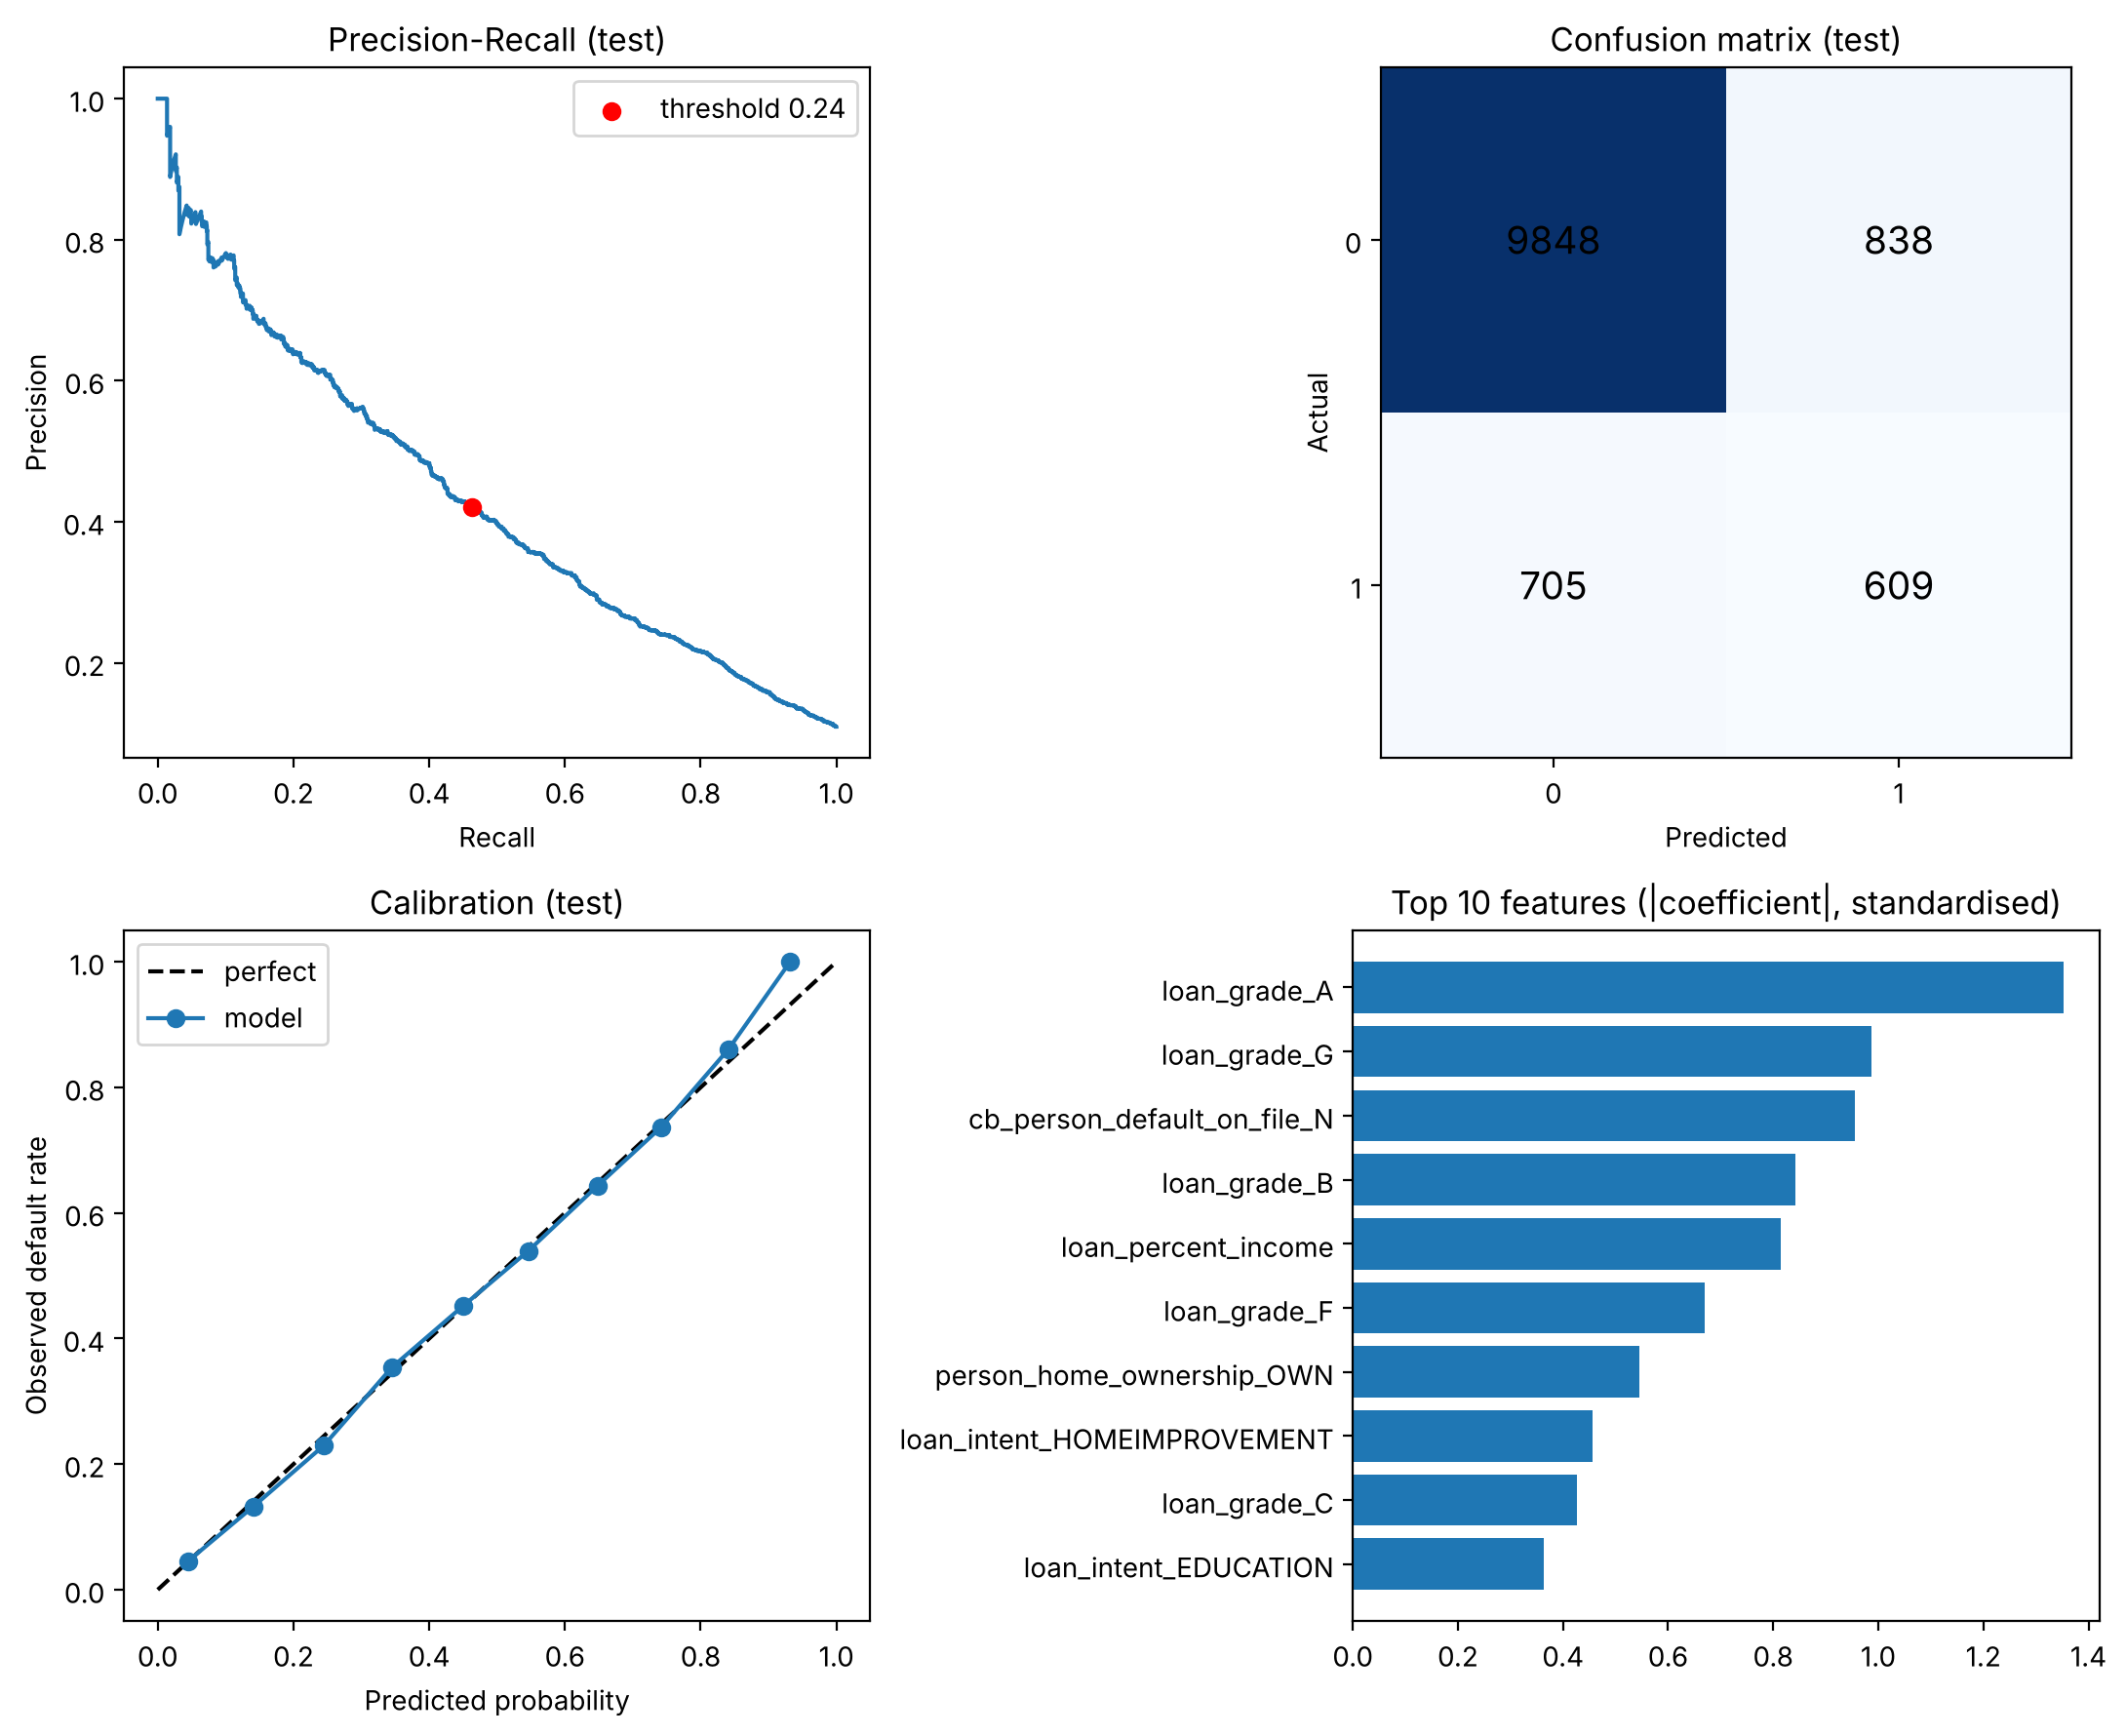

In [25]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(2, 2, figsize=(11, 9))

#1. Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_test, p_te)
ax[0, 0].plot(rec, prec)
pt = classification_metrics(y_test, p_te, threshold)
ax[0, 0].scatter([pt["recall"]], [pt["precision"]], c="red", zorder=3, label=f"threshold {threshold:.2f}")
ax[0, 0].set(title="Precision-Recall (test)", xlabel="Recall", ylabel="Precision")
ax[0, 0].legend()

#2. Confusion matrix
cm = confusion_matrix(y_test, (p_te >= threshold).astype(int))
ax[0, 1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0, 1].text(j, i, v, ha="center", va="center", fontsize=14)
ax[0, 1].set(title="Confusion matrix (test)", xticks=[0, 1], yticks=[0, 1],
             xlabel="Predicted", ylabel="Actual")

#3. Calibration curve
frac, mean = calibration_curve(y_test, p_te, n_bins=10)
ax[1, 0].plot([0, 1], [0, 1], "k--", label="perfect")
ax[1, 0].plot(mean, frac, "o-", label="model")
ax[1, 0].set(title="Calibration (test)", xlabel="Predicted probability", ylabel="Observed default rate")
ax[1, 0].legend()

#4. Top 10 features
names = final_pipe.named_steps["pre"].get_feature_names_out()
est = final_pipe.named_steps["model"]
if hasattr(est, "feature_importances_"):
    vals, title = est.feature_importances_, "Top 10 features (XGBoost gain)"
else:
    vals, title = np.abs(est.coef_[0]), "Top 10 features (|coefficient|, standardised)"
imp = pd.Series(vals, index=names).nlargest(10)[::-1]
imp.index = [n.split("__", 1)[1] for n in imp.index]
ax[1, 1].barh(imp.index, imp.values)
ax[1, 1].set(title=title)

fig.tight_layout()
REPORT_PATH.parent.mkdir(exist_ok=True)
fig.savefig(REPORT_PATH, dpi=110)
plt.show()

# 12. Save the Final Model

In [26]:
#Save ONE artifact: model + threshold + feature list + library versions
import sklearn
import xgboost

MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump({
    "model": final_pipe,
    "threshold": threshold,
    "features": FEATURES,
    "model_name": best_name,
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}, MODEL_PATH)

['/home/claude/credit_risk_v3/models/credit_risk_model.joblib']

In [27]:
METRICS_PATH.write_text(json.dumps(
    {"selected_model": best_name, "cv": results, "test": test,
     "n_train": len(x_train), "n_test": len(x_test)}, indent=2))
print(f"Saved {MODEL_PATH.relative_to(ROOT)} and {METRICS_PATH.relative_to(ROOT)}")

Saved models/credit_risk_model.joblib and models/metrics.json
